### Fase 1: Limpieza del Log (Data Cleaning)
Al igual que en la vida real, los datos del servidor tienen errores. Utilicen pandas para limpiarlos:

1. Eliminen cualquier fila donde el nombre del producto sea nulo.
2. Estandaricen el formato (todo a MAYÚSCULAS) porque el sistema capturó "Laptop" y "laptop" como cosas distintas.
3. El sistema falló algunas veces y guardó el ticket como "ERR_TIMEOUT". Eliminen esas transacciones.
4. Regla de Negocio (Self-Loops): Si un cliente compró 2 "Teclados" en el mismo ticket por error (filas duplicadas en el mismo ID de Transacción), deben eliminar el duplicado. Para la red, solo nos importa qué productos distintos acompañan a otros, un producto no puede acompañarse a sí mismo.

In [42]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


df = pd.read_csv('compras_ecommerce.csv')
display(df.head())

,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [43]:
# print(df.count())
# print("length: ", df.__len__())

df_clean = df.dropna().copy()
# print(df_clean)

df_clean["Producto"] = df_clean["Producto"].str.strip().str.upper()

# df2 = df_clean[df_clean["ID_Transaccion"] == "ERR_TIMEOUT"]
# print(df2.head())

df_clean = df_clean[df_clean["ID_Transaccion"] != "ERR_TIMEOUT"]
# print(df_clean)

df_clean = df_clean.drop_duplicates(subset=['ID_Transaccion', 'Producto'])



### Fase 2: Extracción (Colapsar el Grafo Bipartito)
Tienen una tabla bipartita implícita (Tickets -> Productos). Deben colapsarla para conectar Producto -> Producto.

Utilicen pd.merge() para unir su dataframe limpio consigo mismo utilizando ID_Transaccion como llave de cruce.
Filtren la tabla resultante para eliminar las conexiones de un producto consigo mismo, y eviten aristas duplicadas (no queremos contar "Mouse-Laptop" y luego "Laptop-Mouse" por separado).
Agrupen (groupby) el resultado para contar cuántas veces ocurrió cada par. Ese conteo será su columna Peso.

In [44]:
pares = df_clean.merge(
    df_clean, 
    on='ID_Transaccion', 
    suffixes=('_A', '_B')
)

pares = pares[pares['Producto_A'] < pares['Producto_B']]
aristas = pares.groupby(['Producto_A', 'Producto_B']).size().reset_index(name='peso')

display(aristas)

,Producto_A,Producto_B,peso
0,AUDÍFONOS BLUETOOTH,CABLE HDMI 2.1,21
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341
2,AUDÍFONOS BLUETOOTH,MICRÓFONO DE CONDENSADOR,21
3,AUDÍFONOS BLUETOOTH,"MONITOR 27"" 144HZ",20
4,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO,334
5,AUDÍFONOS BLUETOOTH,MOUSEPAD XL,23
6,AUDÍFONOS BLUETOOTH,SILLA GAMER ERGONÓMICA,17
7,AUDÍFONOS BLUETOOTH,TECLADO MECÁNICO RGB,26
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
9,CABLE HDMI 2.1,LAPTOP PRO 15,25


### Fase 3: Respuestas de Negocio (El Veredicto)
Pasen su tabla extraída a networkx (nx.from_pandas_edgelist) y respondan mediante código a su director de ventas:

La Joya de la Corona: Usando la métrica de Degree Centrality (nx.degree_centrality), ¿Cuál es el "Producto Ancla" o "Hub" de su tienda? (Este es el producto que deben poner en la portada de la página web porque es el que más incita a comprar otras cosas).
El Algoritmo en Acción: Revisen los pesos de sus aristas (o el diccionario de vecinos del grafo). Si un cliente acaba de meter un "TECLADO MECÁNICO RGB" a su carrito, ¿cuál es el producto exacto que el sistema debe recomendarle automáticamente para maximizar la probabilidad de venta conjunta?
Renderizado: Dibujen el grafo, haciendo que el grosor de las líneas (width) sea proporcional al Peso de la conexión. Visualmente comprobarán su algoritmo.

In [45]:
G = nx.from_pandas_edgelist(
aristas, 
    source='Producto_A', 
    target='Producto_B', 
    edge_attr='peso'
)

grafo = nx.degree_centrality(G)
print("Centralidad de Grado: ", grafo)


Centralidad de Grado:  {'AUDÍFONOS BLUETOOTH': 1.0, 'CABLE HDMI 2.1': 1.0, 'LAPTOP PRO 15': 1.0, 'MICRÓFONO DE CONDENSADOR': 1.0, 'MONITOR 27" 144HZ': 1.0, 'MOUSE INALÁMBRICO': 1.0, 'MOUSEPAD XL': 1.0, 'SILLA GAMER ERGONÓMICA': 1.0, 'TECLADO MECÁNICO RGB': 1.0, 'WEBCAM 1080P': 1.0}


In [46]:
producto_ancla = max(grafo, key=grafo.get)

print("Producto Ancla:", producto_ancla)
print("Centralidad:", grafo[producto_ancla])

Producto Ancla: AUDÍFONOS BLUETOOTH
Centralidad: 1.0


In [47]:
producto = "TECLADO MECÁNICO RGB"

if producto in G:
    vecinos = G[producto]

    recomendaciones = sorted(
        vecinos.items(),
        key=lambda x: x[1]['peso'],
        reverse=True
    )

    print("Recomendaciones para:", producto)

    for nombre, datos in recomendaciones:
        print(nombre, "- Peso:", datos['peso'])

    if recomendaciones:
        print("Mejor recomendación:", recomendaciones[0][0])
else:
    print("El producto no se encuentra en el grafo.")

Recomendaciones para: TECLADO MECÁNICO RGB
MOUSEPAD XL - Peso: 359
SILLA GAMER ERGONÓMICA - Peso: 351
MONITOR 27" 144HZ - Peso: 350
MOUSE INALÁMBRICO - Peso: 37
WEBCAM 1080P - Peso: 34
CABLE HDMI 2.1 - Peso: 33
LAPTOP PRO 15 - Peso: 33
MICRÓFONO DE CONDENSADOR - Peso: 29
AUDÍFONOS BLUETOOTH - Peso: 26
Mejor recomendación: MOUSEPAD XL


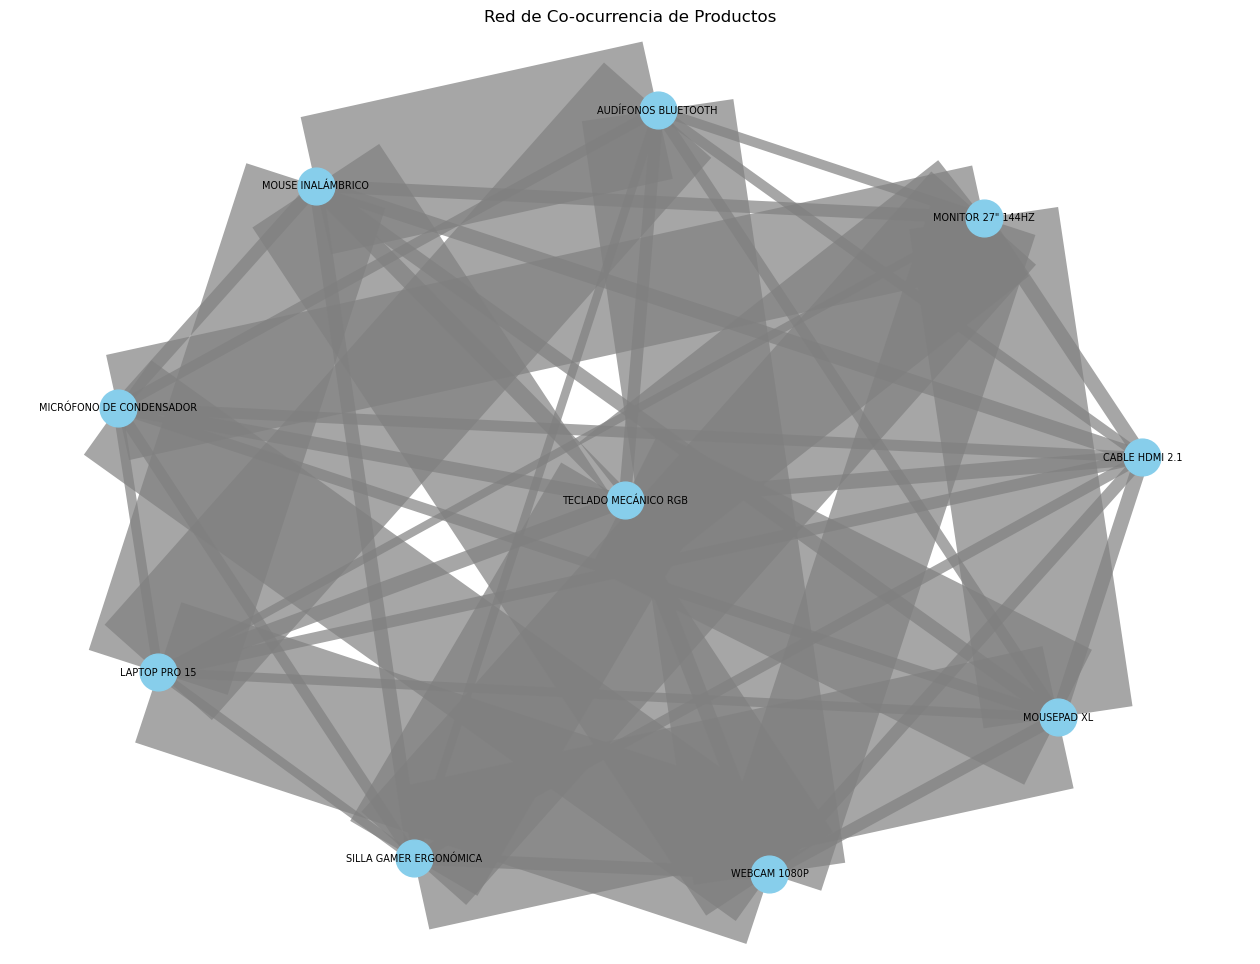

In [49]:

plt.figure(figsize=(16, 12))


pos = nx.spring_layout(G, k=1.5, iterations=100, seed=42)


pesos = [G[u][v]['peso'] for u, v in G.edges()]


anchos = [1 + (peso * 0.3) for peso in pesos]


nx.draw_networkx_edges(
    G, pos,
    width=anchos,
    edge_color='gray',
    alpha=0.7
)

nx.draw_networkx_nodes(
    G, pos,
    node_size=700,
    node_color='skyblue'
)
nx.draw_networkx_labels(
    G, pos,
    font_size=7
)

plt.title("Red de Co-ocurrencia de Productos")
plt.axis('off')
plt.show()
